# Seattle Housing Prices — сравнительный анализ градиентных бустингов

**Pet project | Regression · Gradient Boosting · Hyperparameter Analysis · Model Ensembling**

## Актуальность и проблема

Прогнозирование стоимости недвижимости по характеристикам объекта — прикладная задача регрессии. Помимо точности важны устойчивость к изменению гиперпараметров, склонность к переобучению и вычислительные затраты. Разные библиотеки градиентного бустинга могут существенно различаться по этим характеристикам.

**Цель:** сравнить `GradientBoostingRegressor`, `XGBRegressor`, `LGBMRegressor` и `CatBoostRegressor` на данных о продажах жилья в Сиэтле; исследовать чувствительность к числу деревьев, глубине, скорости обучения и регуляризации; сопоставить время обучения и предсказания; изучить объединение моделей.

**Данные:** локальный файл `houses_train.csv` с характеристиками недвижимости и целевой переменной `price`. Файл не входит в предоставленный ноутбук; для повторного запуска его необходимо добавить отдельно. Из анализа исключены `id`, `date` и `zipcode`.

**Основная метрика — MAPE:** средняя абсолютная процентная ошибка прогноза. В графиках используется реализация с умножением на 100 (значения в процентах), а в эксперименте со стекингом — `sklearn.metrics.mean_absolute_percentage_error` (доли единицы). Эти значения **нельзя напрямую сравнивать без пересчёта**.

**Методы:** четыре реализации градиентного бустинга; исследование train/validation MAPE при изменении гиперпараметров; визуализация отдельных деревьев; измерение времени; эксперимент с линейной метамоделью.

**Воспроизводимость:** сохранены исходные кодовые ячейки и их существующие результаты. Код в этом файле не перезапускался. Результаты относятся к выполненному ранее эксперименту.

> **Ограничение эксперимента со стекингом:** в исходном коде второе разбиение заново выполняется на полном наборе `X, y`, а не на оставшейся части после первого разбиения. Это создаёт пересечение train/validation/test и делает оценку стекинга потенциально смещённой. Выводы о его превосходстве делать нельзя до исправления разбиения и повторной оценки.


## 1. Данные и подготовка признаков

### Датасет
Используются характеристики продаж жилья в Сиэтле (`houses_train.csv`); целевая переменная — `price`.

Данные имеют следующие столбцы:
* `id` — идентификационный номер жилья
* `date` — дата продажи дома
* `price` — цена
* `bedrooms` — количество спален
* `bathrooms` — количество ванных комнат, где .5 означает комнату с туалетом, но без душа
* `sqft_living` — площадь жилья
* `sqft_lot` — площадь участка
* `floors` — количество этажей
* `waterfront` — видна ли набережная
* `view` — насколько хороший вид
* `condition` — индекс от 1 от 5, отвечающий за состояние квартиры
* `grade` — 1 до 13, 1-3 соответствует плохому уровню строительства и дизайна, 3-7 — средний уровень, 11-13 — высокий.
* `sqft_above` — жилая площадь над уровнем земли
* `sqft_basement` — жилая площадь под уровнем земли
* `yr_built` — год постройки жилья
* `yr_renovated` — год последней реконструкции жилья
* `zipcode` — почтовый индекс
* `lat` — широта
* `long` — долгота
* `sqft_living15` — средняя площадь жилья ближайших 15-и соседей
* `sqft_lot15` — средняя площадь участка ближайших 15-и соседей

В следующей задаче вы будете работать с ними в рамках Kaggle-соревнования. Предлагаем сначала подготовиться к нему, исследовав работу различных бустинг-библиотек применительно к этим данных. Результаты этой задаче вы сможете использовать в качестве начального решения соревнования.

### Дизайн эксперимента
Сравниваются четыре реализации бустинга по MAPE на обучающей и валидационной выборках. Изучается влияние числа деревьев, глубины, `learning_rate`, L1- и L2-регуляризации.

In [2]:
train_df = pd.read_csv(
    'houses_train.csv', parse_dates=['date']
).drop(columns=['id'])
train_df.head()

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,2015-10-13,221900.0,3,1.00,1180,5650,1.0,0,0,3,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,2015-12-09,538000.0,3,2.25,2570,7242,2.0,0,0,3,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,2015-12-09,604000.0,4,3.00,1960,5000,1.0,0,0,5,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
3,2016-02-18,510000.0,3,2.00,1680,8080,1.0,0,0,3,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503
4,2015-06-27,257500.0,3,2.25,1715,6819,2.0,0,0,3,7,1715,0,1995,0,98003,47.3097,-122.327,2238,6819


### Описательная статистика

In [3]:
train_df.describe()

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
count,15626,1.562600e+04,15626.000000,15626.000000,15626.000000,1.562600e+04,15626.000000,15626.000000,15626.000000,15626.000000,15626.000000,15626.000000,15626.000000,15626.000000,15626.000000,15626.000000,15626.000000,15626.000000,15626.000000,15626.000000
mean,2015-10-29 08:46:06.466146048,5.355339e+05,3.371240,2.111737,2073.132919,1.506655e+04,1.494304,0.007488,0.228465,3.408870,7.649878,1785.817868,287.315052,1970.937028,86.066684,98077.961858,47.559655,-122.213479,1980.853897,12689.631384
min,2015-05-02 00:00:00,7.500000e+04,0.000000,0.000000,290.000000,6.000000e+02,1.000000,0.000000,0.000000,1.000000,1.000000,290.000000,0.000000,1900.000000,0.000000,98001.000000,47.155900,-122.519000,399.000000,651.000000
25%,2015-07-22 00:00:00,3.200000e+05,3.000000,1.500000,1430.000000,5.060000e+03,1.000000,0.000000,0.000000,3.000000,7.000000,1190.000000,0.000000,1951.000000,0.000000,98033.000000,47.470225,-122.328000,1480.000000,5100.000000
50%,2015-10-16 00:00:00,4.500000e+05,3.000000,2.250000,1910.000000,7.598500e+03,1.500000,0.000000,0.000000,3.000000,7.000000,1560.000000,0.000000,1975.000000,0.000000,98065.000000,47.571900,-122.230000,1830.000000,7620.000000
75%,2016-02-17 00:00:00,6.400000e+05,4.000000,2.500000,2540.000000,1.057975e+04,2.000000,0.000000,0.000000,4.000000,8.000000,2210.000000,550.000000,1996.750000,0.000000,98118.000000,47.678200,-122.124000,2360.000000,10027.000000
max,2016-05-27 00:00:00,7.700000e+06,11.000000,8.000000,13540.000000,1.651359e+06,3.500000,1.000000,4.000000,5.000000,13.000000,9410.000000,4820.000000,2015.000000,2015.000000,98199.000000,47.777600,-121.315000,5790.000000,871200.000000
std,NaN,3.595051e+05,0.909872,0.769037,911.406092,4.235533e+04,0.539333,0.086209,0.757528,0.651925,1.171214,821.668484,439.948411,29.368239,405.398690,53.598316,0.138845,0.141089,680.403268,27103.989191


In [4]:
train_df.columns

Index(['date', 'price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot',
       'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above',
       'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode', 'lat', 'long',
       'sqft_living15', 'sqft_lot15'],
      dtype='object')

### Отбор признаков

In [5]:
zipcode = train_df['zipcode']
train_df = train_df.drop(columns=['date', 'zipcode'])

### Пространственное распределение объектов

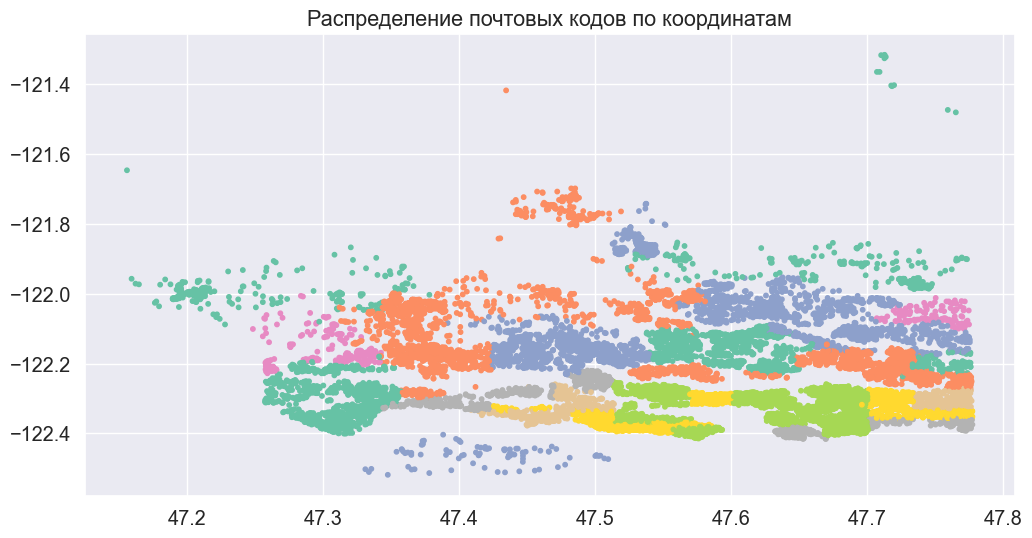

In [6]:
plt.figure(figsize=(12, 6))
plt.scatter(train_df['lat'], train_df['long'],
            c=zipcode, cmap='Set2', s=10);
plt.title('Распределение почтовых кодов по координатам')
plt.show()

### Признаки и целевая переменная

In [7]:
X_all, y_all = train_df.drop(columns=['price']), train_df['price']

### Разделение на обучающую и валидационную выборки

In [8]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X_all, y_all, test_size=0.3, random_state=42
)

### Вспомогательные средства визуализации

In [9]:
colors = ['#FF3300', '#0099CC', '#00CC66', 'orange']

In [10]:
def plot_dependence_test(param_grid, mape_train, mape_valid, descr,
                         param_label, title, log_x_scale=False, ylim=(0.1, 0.2)):
    '''
    Функция для построения графиков зависимости целевой метрики
    от некоторого параметра моделей на обучающей и валидационной выборках.

    Параметры.
    1) param_grid - значения исследуемого параметра,
    2) mape_train - значения метрик на обучающей выборке,
    3) mape_train - значения метрик на валидационной выборке,
    4) descr - описания моделей для легенды
    5) param_label - названия параметра,
    6) log_x_scale - сделать масштаб по оси x логарифмическим
    7) title - заголовок для графика.
    '''

    plt.figure(figsize=(16, 9))

    for i in range(len(mape_train)):
        plt.plot(param_grid, mape_train[i], color=colors[i],
                 linewidth=2, alpha=0.7, linestyle='--',
                 label=f'{descr[i]} train')
        plt.plot(param_grid, mape_valid[i], color=colors[i],
                 linewidth=4, alpha=0.7,
                 label=f'{descr[i]} valid')

    plt.xlabel(param_label)
    plt.ylabel('MAPE, %')
    plt.legend(ncol=2)
    plt.title(title)
    if log_x_scale:
        plt.xscale('log')
    plt.ylim(ylim)
    plt.show()

## 2. Влияние количества деревьев

In [11]:
def mape(y_true, y_pred):
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    eps = 1e-8
    return np.mean(np.abs((y_true - y_pred) / (y_true + eps))) * 100


In [13]:
mape_train = []
mape_valid = []
n_estimators_grid = np.arange(1, 1000)

# GB sklearn
regressor = GradientBoostingRegressor(n_estimators=max(n_estimators_grid))
regressor.fit(X_train, y_train)
mape_train.append([mape(y_train, p) for p in regressor.staged_predict(X_train)])
mape_valid.append([mape(y_valid, p) for p in regressor.staged_predict(X_valid)])

# XGBoost
regressor = XGBRegressor(n_estimators=max(n_estimators_grid))
regressor.fit(X_train, y_train)
mape_train.append([
    mape(y_train, regressor.predict(X_train, iteration_range=(0, i+1)))
    for i in range(max(n_estimators_grid))
])
mape_valid.append([
    mape(y_valid, regressor.predict(X_valid, iteration_range=(0, i+1)))
    for i in range(max(n_estimators_grid))
])

# LightGBM
regressor = LGBMRegressor(n_estimators=max(n_estimators_grid))
regressor.fit(X_train, y_train)
mape_train.append([
    mape(y_train, regressor.predict(X_train, num_iteration=i+1))
    for i in range(max(n_estimators_grid))
])
mape_valid.append([
    mape(y_valid, regressor.predict(X_valid, num_iteration=i+1))
    for i in range(max(n_estimators_grid))
])

# CatBoost
regressor = CatBoostRegressor(n_estimators=max(n_estimators_grid), silent=True)
regressor.fit(X_train, y_train)
mape_train.append([
    mape(y_train, regressor.predict(X_train, ntree_end=i+1))
    for i in range(max(n_estimators_grid))
])
mape_valid.append([
    mape(y_valid, regressor.predict(X_valid, ntree_end=i+1))
    for i in range(max(n_estimators_grid))
])

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000796 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2211
[LightGBM] [Info] Number of data points in the train set: 10938, number of used features: 17
[LightGBM] [Info] Start training from score 533390.492138


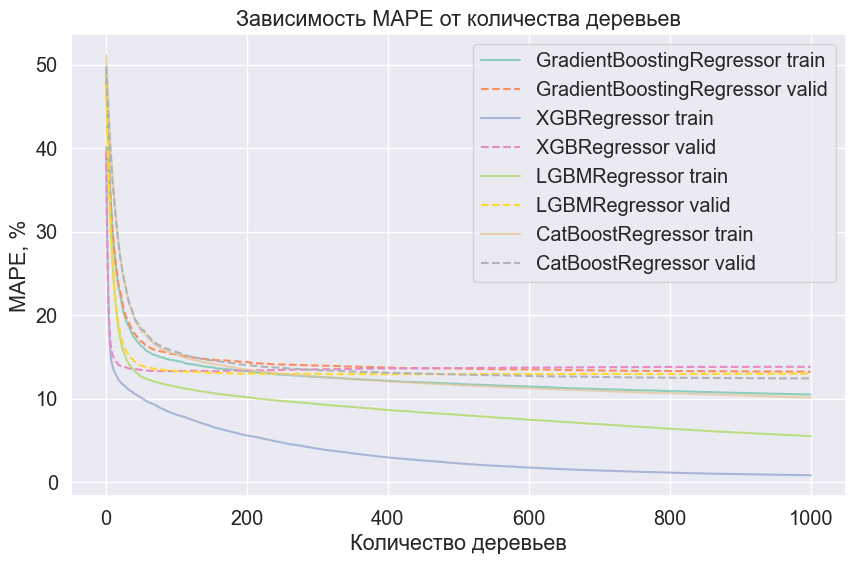

In [14]:
models = ['GradientBoostingRegressor', 'XGBRegressor',
          'LGBMRegressor', 'CatBoostRegressor']

plt.figure(figsize=(10, 6))
for i, name in enumerate(models):
    plt.plot(n_estimators_grid, mape_train[i], label=f'{name} train', alpha=0.7)
    plt.plot(n_estimators_grid, mape_valid[i], label=f'{name} valid', linestyle='--')

plt.xlabel('Количество деревьев')
plt.ylabel('MAPE, %')
plt.title('Зависимость MAPE от количества деревьев')
plt.legend()
plt.grid(True)
plt.show()


**Вывод:** XGBoost и LightGBM позволяет быстро получить довольно приемлемое качество на небольшом количестве деревьев. Однако при увеличении количества деревьев они начинают переобучаться. Реализации из sklearn и CatBoost'у требуется большое количество деревьев для получения хорошего качества, причем при увеличении количества деревьев не наблюдается переобучения. Подобные свойства наблюдаются у реализации из sklearn. Наилучшее качество на валидационной выборке позволяет получить CatBoost.

## 3. Влияние максимальной глубины

In [ ]:
max_depth_grid = np.arange(2, 12)

mape_train, mape_valid = np.zeros((2, 4, len(max_depth_grid)))

for i, max_depth in tqdm(enumerate(max_depth_grid), total=len(max_depth_grid)):
    # GB sklearn
    regressor = GradientBoostingRegressor(max_depth=max_depth)
    regressor.fit(X_train, y_train)
    mape_train[0, i] = mape(y_train, regressor.predict(X_train))
    mape_valid[0, i] = mape(y_valid, regressor.predict(X_valid))

    # XGBoost
    regressor = XGBRegressor(max_depth=max_depth)
    regressor.fit(X_train, y_train)
    mape_train[1, i] = mape(y_train, regressor.predict(X_train))
    mape_valid[1, i] = mape(y_valid, regressor.predict(X_valid))

    # LightGBM
    regressor = LGBMRegressor(max_depth=max_depth)
    regressor.fit(X_train, y_train)
    mape_train[2, i] = mape(y_train, regressor.predict(X_train))
    mape_valid[2, i] = mape(y_valid, regressor.predict(X_valid))

    # CatBoost
    regressor = CatBoostRegressor(max_depth=max_depth, silent=True)
    regressor.fit(X_train, y_train)
    mape_train[3, i] = mape(y_train, regressor.predict(X_train))
    mape_valid[3, i] = mape(y_valid, regressor.predict(X_valid))

  0%|          | 0/10 [00:00<?, ?it/s]

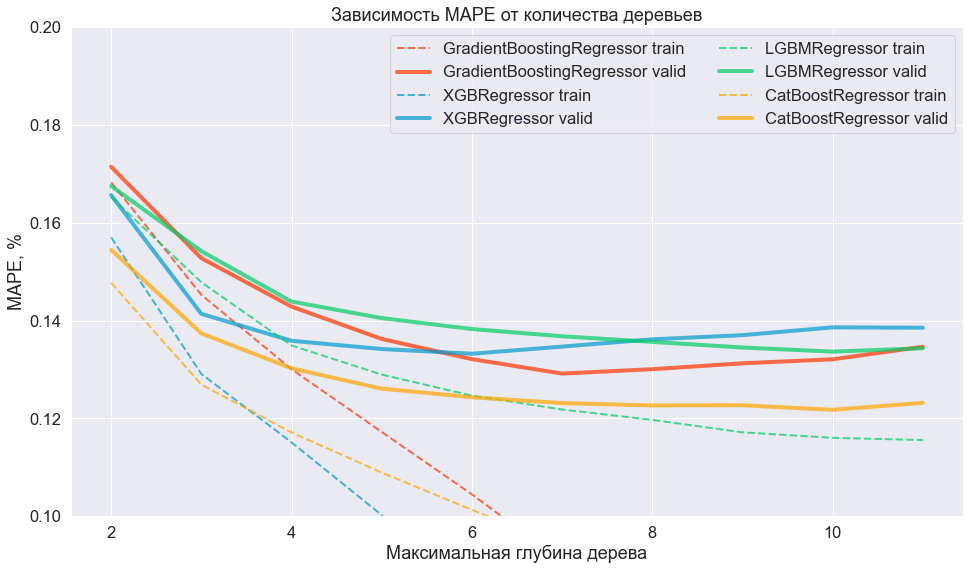

In [ ]:
plot_dependence_test(
    param_grid=max_depth_grid,
    mape_train=mape_train,
    mape_valid=mape_valid,
    descr=['GradientBoostingRegressor', 'XGBRegressor',
           'LGBMRegressor', 'CatBoostRegressor'],
    param_label='Максимальная глубина дерева',
    title='Зависимость MAPE от количества деревьев',
)

**Вывод:** Оптимальная глубина дерева для разных моделей равна от 5 до 8. Модели XGBoost и sklearn-реализация начинают переобучаться с увеличением глубины дерева. Модели LightGBM и CatBoost ведут себя более устойчиво.

## 4. Влияние learning rate

In [ ]:
learning_rate_grid = np.logspace(np.log10(0.01), np.log10(0.6), 20)

mape_train, mape_valid = np.zeros((2, 4, len(learning_rate_grid)))

for i, learning_rate in tqdm(enumerate(learning_rate_grid),
                             total=len(learning_rate_grid)):
    regressor = GradientBoostingRegressor(learning_rate=learning_rate)
    regressor.fit(X_train, y_train)
    mape_train[0, i] = mape(y_train, regressor.predict(X_train))
    mape_valid[0, i] = mape(y_valid, regressor.predict(X_valid))

    regressor = XGBRegressor(learning_rate=learning_rate)
    regressor.fit(X_train, y_train)
    mape_train[1, i] = mape(y_train, regressor.predict(X_train))
    mape_valid[1, i] = mape(y_valid, regressor.predict(X_valid))

    regressor = LGBMRegressor(learning_rate=learning_rate)
    regressor.fit(X_train, y_train)
    mape_train[2, i] = mape(y_train, regressor.predict(X_train))
    mape_valid[2, i] = mape(y_valid, regressor.predict(X_valid))

    regressor = CatBoostRegressor(learning_rate=learning_rate, silent=True)
    regressor.fit(X_train, y_train)
    mape_train[3, i] = mape(y_train, regressor.predict(X_train))
    mape_valid[3, i] = mape(y_valid, regressor.predict(X_valid))

  0%|          | 0/20 [00:00<?, ?it/s]

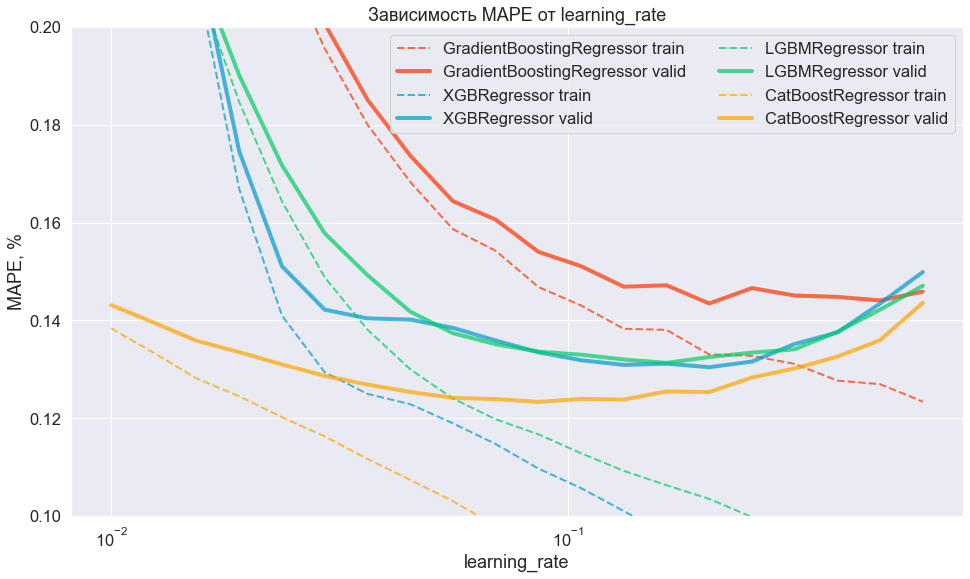

In [ ]:
plot_dependence_test(
    param_grid=learning_rate_grid,
    mape_train=mape_train,
    mape_valid=mape_valid,
    descr=['GradientBoostingRegressor', 'XGBRegressor',
           'LGBMRegressor', 'CatBoostRegressor'],
    param_label='learning_rate',
    title='Зависимость MAPE от learning_rate',
    log_x_scale=True,
)

**Вывод:** Для каждой модели наблюдается некоторое оптимальное значение `learning_rate`. При меньших значениях модели недообучаются, при больших значениях наблюдается ухудшение качество и некоторое колебание результатов. Модель CatBoost показывает наилучшее качество.

## 5. L2-регуляризация

В этом эксперименте оценивается чувствительность моделей к коэффициенту L2-регуляризации.

In [ ]:
l2_grid = np.logspace(-3, 3, 20)

mape_train, mape_valid = np.zeros((2, 3, len(l2_grid)))

for i, l2_coef in tqdm(enumerate(l2_grid), total=len(l2_grid)):
    regressor = XGBRegressor(reg_lambda=l2_coef)
    regressor.fit(X_train, y_train)
    mape_train[0, i] = mape(y_train, regressor.predict(X_train))
    mape_valid[0, i] = mape(y_valid, regressor.predict(X_valid))

    regressor = LGBMRegressor(reg_lambda=l2_coef)
    regressor.fit(X_train, y_train)
    mape_train[1, i] = mape(y_train, regressor.predict(X_train))
    mape_valid[1, i] = mape(y_valid, regressor.predict(X_valid))

    regressor = CatBoostRegressor(l2_leaf_reg=l2_coef, silent=True)
    regressor.fit(X_train, y_train)
    mape_train[2, i] = mape(y_train, regressor.predict(X_train))
    mape_valid[2, i] = mape(y_valid, regressor.predict(X_valid))

  0%|          | 0/20 [00:00<?, ?it/s]

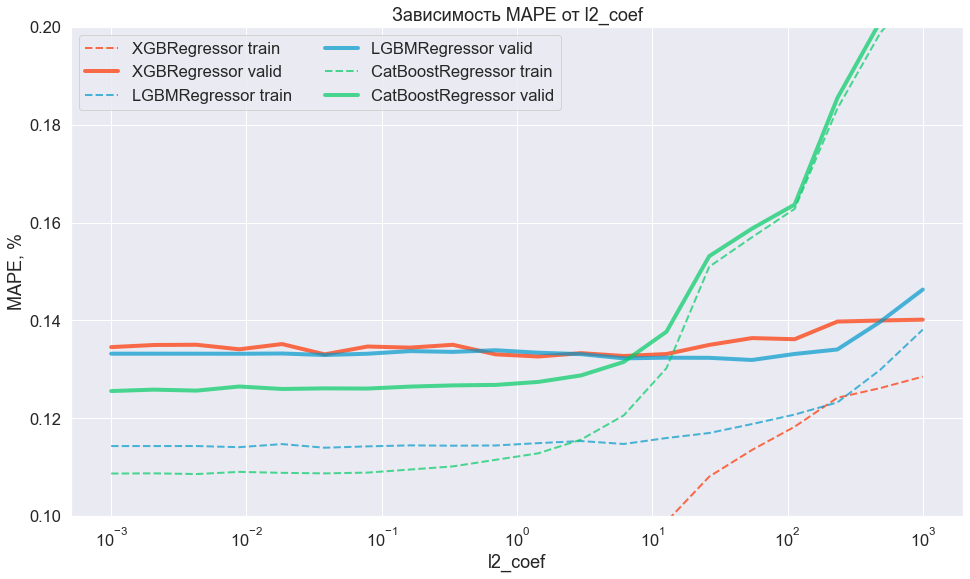

In [ ]:
plot_dependence_test(
    param_grid=l2_grid,
    mape_train=mape_train,
    mape_valid=mape_valid,
    descr=['XGBRegressor', 'LGBMRegressor', 'CatBoostRegressor'],
    param_label='l2_coef',
    title='Зависимость MAPE от l2_coef',
    log_x_scale=True,
)

**Вывод:** Для всех моделей кроме CatBoost сложно заметить влияние данного параметра.

## 6. L1-регуляризация

Для XGBoost и LightGBM дополнительно исследуется влияние L1-регуляризации.

In [ ]:
l1_grid = np.logspace(-3, 3, 20)

mape_train, mape_valid = np.zeros((2, 2, len(l1_grid)))

for i, l1_coef in tqdm(enumerate(l1_grid), total=len(l1_grid)):
    regressor = XGBRegressor(reg_alpha=l1_coef)
    regressor.fit(X_train, y_train)
    mape_train[0, i] = mape(y_train, regressor.predict(X_train))
    mape_valid[0, i] = mape(y_valid, regressor.predict(X_valid))

    regressor = LGBMRegressor(reg_alpha=l1_coef)
    regressor.fit(X_train, y_train)
    mape_train[1, i] = mape(y_train, regressor.predict(X_train))
    mape_valid[1, i] = mape(y_valid, regressor.predict(X_valid))

  0%|          | 0/20 [00:00<?, ?it/s]

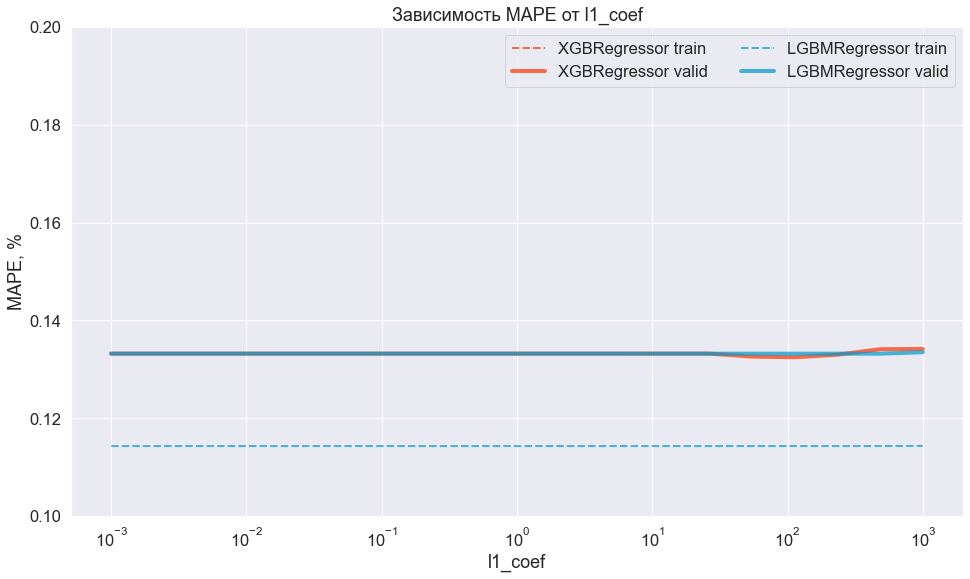

In [ ]:
plot_dependence_test(
    param_grid=l1_grid,
    mape_train=mape_train,
    mape_valid=mape_valid,
    descr=['XGBRegressor', 'LGBMRegressor'],
    param_label='l1_coef',
    title='Зависимость MAPE от l1_coef',
    log_x_scale=True,
)

**Вывод:** Влияние этого параметра так же не очень значительно.

## 7. Интерпретация деревьев разных реализаций

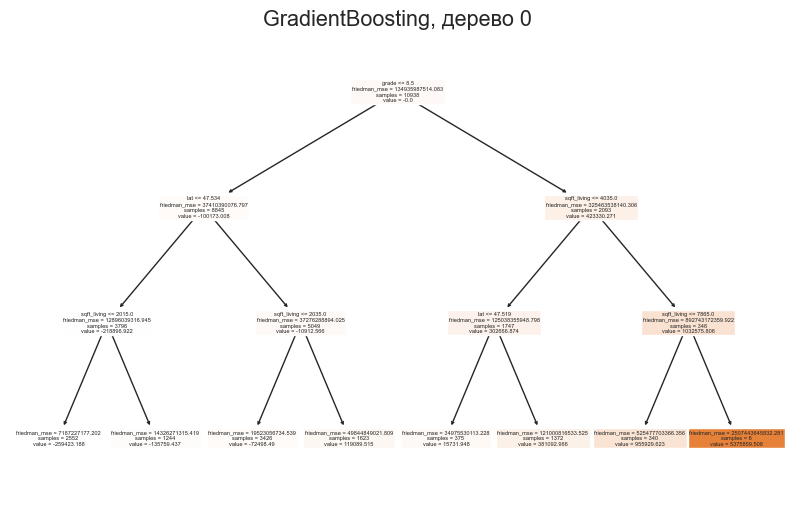

In [ ]:
gb = GradientBoostingRegressor(max_depth=3, n_estimators=5)
gb.fit(X_train, y_train)
plt.figure(figsize=(10, 6))
plot_tree(gb.estimators_[0, 0], filled=True, feature_names=X_train.columns)
plt.title("GradientBoosting, дерево 0")
plt.show()

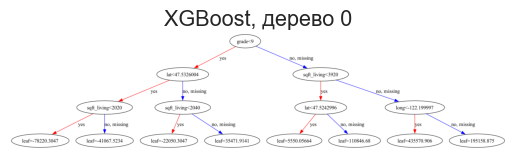

In [ ]:
xgb = XGBRegressor(max_depth=3, n_estimators=5)
xgb.fit(X_train, y_train)
xgb_plot_tree(xgb, num_trees=0)
plt.title("XGBoost, дерево 0")
plt.show()

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000894 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2211
[LightGBM] [Info] Number of data points in the train set: 10938, number of used features: 17
[LightGBM] [Info] Start training from score 533390.492138
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf


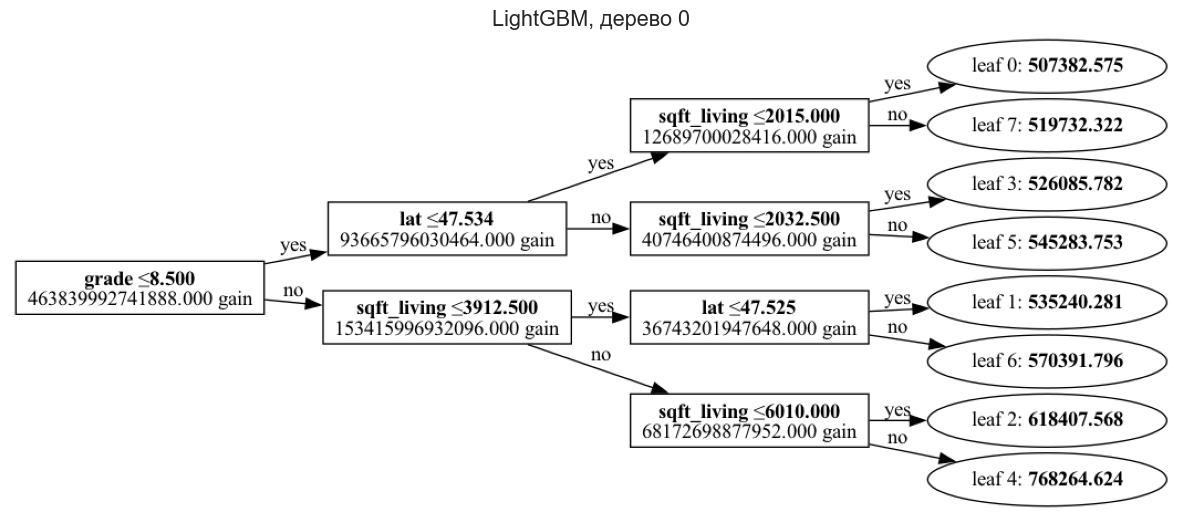

In [ ]:
lgb = LGBMRegressor(max_depth=3, n_estimators=5)
lgb.fit(X_train, y_train)
lgb_plot_tree(lgb, tree_index=0, figsize=(15, 8), show_info=['split_gain'])
plt.title("LightGBM, дерево 0")
plt.show()

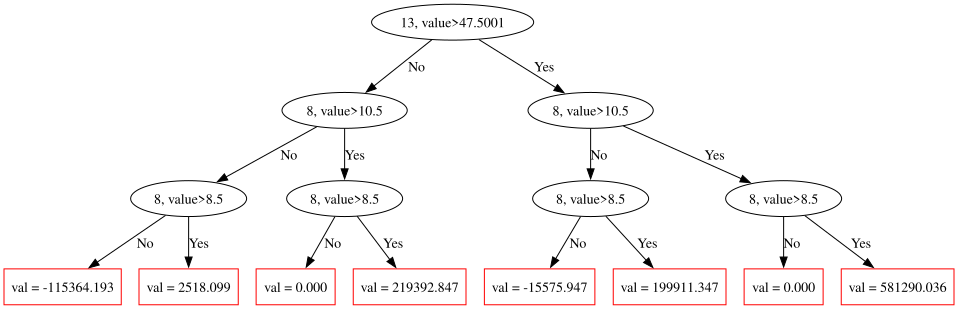

In [ ]:
cat = CatBoostRegressor(max_depth=3, n_estimators=5, silent=True)
cat.fit(X_train, y_train)
cat.plot_tree(tree_idx=0)

## 8. Время обучения и инференса

In [ ]:
models = {
    "GradientBoosting": GradientBoostingRegressor(max_depth=3, n_estimators=300, learning_rate=0.05),
    "XGBoost": XGBRegressor(max_depth=3, n_estimators=300, learning_rate=0.05, verbosity=0),
    "LightGBM": LGBMRegressor(max_depth=3, n_estimators=300, learning_rate=0.05, num_leaves=7, force_row_wise=True),
    "CatBoost": CatBoostRegressor(max_depth=3, n_estimators=300, learning_rate=0.05, silent=True)
}

train_times, pred_times, mape_vals = {}, {}, {}

for name, model in models.items():
    # время обучения
    start = time.perf_counter()
    model.fit(X_train, y_train)
    train_time = time.perf_counter() - start

    # время предсказания
    start = time.perf_counter()
    preds = model.predict(X_valid)
    pred_time = time.perf_counter() - start

    # метрика
    m = mape(y_valid, preds)

    train_times[name] = train_time
    pred_times[name] = pred_time
    mape_vals[name] = m

for name in models:
    print(f"{name:15s} | train: {train_times[name]:.3f}s | predict: {pred_times[name]:.3f}s | MAPE: {mape_vals[name]:.3f}")

[LightGBM] [Info] Total Bins 2211
[LightGBM] [Info] Number of data points in the train set: 10938, number of used features: 17
[LightGBM] [Info] Start training from score 533390.492138
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best g

**Выводы:**

Современные реализации бустинга (XGBoost, LightGBM, CatBoost) обучаются в 15–20 раз быстрее классического `GradientBoostingRegressor`, сохраняя то же качество предсказаний.
XGBoost показывает наилучший баланс между скоростью и точностью, LightGBM обучается быстрее всех благодаря leaf-wise росту деревьев, а CatBoost стабилен и естественно работает с категориальными признаками.
По структуре деревьев: у sklearn и XGBoost — обычные несбалансированные бинарные CART-деревья, у LightGBM — несимметричные и глубокие leaf-wise, у CatBoost — симметричные oblivious-деревья.
Если в лист CatBoost не попадают объекты, он присваивает ему сглаженное значение, близкое к нулю, что предотвращает переобучение.


## 9. Эксперимент с линейной метамоделью

### Подход к объединению моделей
В качестве метамодели используется линейная регрессия.

Мета-модель является линейной

### Протокол эксперимента
Базовые модели: XGBoost, LightGBM и CatBoost; метамодель: линейная регрессия. **Внимание:** в исходном разбиении ниже есть пересечение выборок, поэтому приведённые оценки нельзя интерпретировать как независимый тест.

### Загрузка данных

In [24]:
data = pd.read_csv(
    'houses_train.csv', parse_dates=['date']
).drop(columns=['id', 'date', 'zipcode'])

### Признаки и целевая переменная

In [25]:
X, y = data.drop(columns=['price']), data['price']

### Разбиение данных
**Ограничение:** второе разбиение выполняется на полном датасете. Результаты этой секции следует считать иллюстративными; для корректного тестирования нужен новый запуск с непересекающимися выборками.

In [26]:
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X, y, test_size=0.5, random_state=42)

### Обучение базовых моделей

In [27]:
xgb_model = XGBRegressor().fit(X_train, y_train)
lgb_model = LGBMRegressor().fit(X_train, y_train)
cb_model = CatBoostRegressor(verbose=0).fit(X_train, y_train)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000629 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2246
[LightGBM] [Info] Number of data points in the train set: 12500, number of used features: 17
[LightGBM] [Info] Start training from score 533758.884160


### Предсказания базовых моделей

In [28]:
xgb_pred = xgb_model.predict(X_val)
lgb_pred = lgb_model.predict(X_val)
cb_pred = cb_model.predict(X_val)

### Признаки для метамодели

In [29]:
stacked_features = np.column_stack((xgb_pred, lgb_pred, cb_pred))

### Обучение метамодели

In [30]:
meta_model = LinearRegression().fit(stacked_features, y_val)
final_pred = meta_model.predict(stacked_features)

### Оценка на данных метамодели (не независимый тест)

In [31]:
print("MAPE стекинга: {:.3f}".format(mean_absolute_percentage_error(y_val, final_pred)))

MAPE стекинга: 0.084


### Предсказания на обозначенной тестовой части

In [32]:
xgb_pred_test = xgb_model.predict(X_test)
lgb_pred_test = lgb_model.predict(X_test)
cb_pred_test = cb_model.predict(X_test)

In [33]:
stacked_features_test = np.column_stack((xgb_pred_test, lgb_pred_test, cb_pred_test))

In [34]:
test_pred = meta_model.predict(stacked_features_test)

In [35]:
print("MAPE стекинга: {:.3f}".format(mean_absolute_percentage_error(y_test, test_pred)))

MAPE стекинга: 0.106


### Интерпретация результата
Показанные ниже метрики сохранены из исходного эксперимента, но из-за пересечения выборок не подтверждают улучшение качества.

### Ограничения

Стекинг потенциально полезен, однако текущий эксперимент не позволяет количественно подтвердить выигрыш из-за ошибки разбиения.

## Итоги и дальнейшее развитие


**Дальнейшая работа:** корректный out-of-fold stacking, непересекающийся holdout, подбор гиперпараметров по CV, анализ ошибок по ценовым сегментам.